# XKFX - exogenous transmission capacity from 2035

Builds the GAMS input that adds the planned transmission capacity of the Excel reference grid file (`20231103 - Electricity and Hydrogen Reference Grid & Investment Candidates.xlsx`) to the existing `XKFX` table as **exogenous** capacity from 2035. No endogenous investment is needed for these lines.

| Step | What happens |
|---|---|
| 1 | Settings and decisions (all choices are in the first code cell) |
| 2 | Read the current `XKFX.inc` (existing grid) and the Excel tabs *1. Elec Ref Grid* and *3. Elec Invest Candidates* |
| 3 | Map Excel nodes to model regions, split Germany and Norway over their sub-regions |
| 4 | Compare the Excel reference grid with the current `XKFX` |
| 5 | Sum the candidates per border and direction for every stage |
| 6 | Write the new table and the assignment lines to a GAMS `.inc` file |

The model reads `XKFX(Y,IRE,IRI)` per simulated year (flow limit `XKFX + VXKNACCUMNET`), so adding the new capacity to `XKFX` for the later years is enough. The directions are kept separate: *direct* capacity increase is the first-named region sending to the second, *indirect* the reverse.

In [46]:
import re
import collections
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

# ---- paths ------------------------------------------------------------------
ROOT = Path(r"C:\Balmorel")
EXCEL = ROOT / "20231103 - Electricity and Hydrogen Reference Grid & Investment Candidates.xlsx"
XKFX_FILE = ROOT / "base" / "data" / "XKFX.inc"
XMAXINV_FILE = ROOT / "base" / "data" / "XMAXINV.inc"      # only used for the cross-check in section 7
BACKUP_FILE = ROOT / "base" / "data" / "XKFX_before_exogenous.inc"      # copy of the original XKFX.inc, made once before the first modification
WRITE_FILES = True       # True: XKFX.inc is modified (the generated block is replaced if it is already there)

# ---- option inside XKFX.inc ---------------------------------------------------
# The new capacity is added to XKFX.inc as a block that is only active when the GAMS option below is `yes`.
# It can be set in balopt.opt (`$setglobal XKFX_EXOGENOUS yes`) or by editing the line in XKFX.inc.
SWITCH = "XKFX_EXOGENOUS"
ACTIVATE_BY_DEFAULT = False     # value used when the option is not set anywhere else (False = block is present but inactive)

# ---- decision 1: stages ------------------------------------------------------
# {first model year the capacity applies : last candidate year that is included}
# The table of a stage is cumulative (all candidates up to the cut-off year) and is added to the existing XKFX.
# Years between two stages use the earlier stage. Years before the first stage keep the current XKFX.
STAGES = {2035: 2035}
# Example with a second step:  STAGES = {2035: 2035, 2040: 2040}

# ---- decision 2: which candidates ---------------------------------------------
CANDIDATE_TYPES = ["Real", "Concept"]    # name of the candidate = "<border> <type> <n>"
CANDIDATE_SCENARIOS = ["All"]            # column SCENARIO of the Excel tab

# ---- decision 3: mapping of Excel nodes to model regions ------------------------
# Nodes that map to one model region. Everything else follows the prefix rules and the first two letters.
NODE_TO_REGION = {"DKW1": "DK1", "DKE1": "DK2", "FI00": "FIN", "SE01": "SE1", "SE02": "SE2", "SE03": "SE3", "SE04": "SE4"}
PREFIX_TO_REGION = {"IT": "IT", "LU": "LU", "UK": "UK", "PL": "PL", "GR": "GR", "FR": "FR"}   # sub-nodes collapse to one region
# Nodes that are split over several model regions: the Excel node can land in any of the listed regions.
SPLIT_NODES = {
    "DE00": ["DE4-E", "DE4-N", "DE4-S", "DE4-W"],
    "NOS0": ["NO1", "NO2", "NO5"],     # southern Norway
    "NOM1": ["NO3"],                   # mid Norway
    "NON1": ["NO4"],                   # northern Norway
}
# Excel nodes without a model counterpart: borders to these nodes are dropped (nodes outside the model are also dropped automatically)
DROP_NODES = {"DEKF", "DKKF"}          # Kriegers Flak offshore nodes

# ---- decision 4: how a border of a split node is divided over the sub-regions -------
# Default: in proportion to the existing XKFX capacity between the possible region pairs.
# Where there is no existing capacity (or you disagree), give the shares explicitly:
#   (excel node A, excel node B): {(model region A, model region B): share}   shares are normalised
SPLIT_OVERRIDE = {
    ("DE00", "UK00"): {("DE4-N", "UK"): 1.0},      # assumption to review: a link to the UK lands in the north of Germany
}

# ---- decision 5: manual corrections of the existing grid ---------------------------
# Added to the new table of every stage, directed MW: (from region, to region): MW. Use it where XKFX differs from the Excel
# reference grid (see section 4), e.g. {("DE4-N", "UK"): 1400, ("UK", "DE4-N"): 1400}
MANUAL_ADJUSTMENTS = {}

# ---- decision 6: differences with the current XMAXINV --------------------------------
# The current XMAXINV (existing grid + candidates up to 2035) is compared with the new input in the last step.
# False: the differences are only reported, nothing is added to the new capacity.
# True:  where XMAXINV is higher than existing XKFX + new capacity, the gap is added to the new capacity (both directions).
ADD_XMAXINV_DIFFERENCES = True
# True: candidate capacity on a region pair where XMAXINV has no entry (0) is left out, so the new XKFX only contains pairs
# that XMAXINV also covers (the borders the Excel adds but XMAXINV lacks, e.g. DE-UK and FIN-SE2, are then not added).
ONLY_PAIRS_IN_XMAXINV = True

# ---- decision 7: output ------------------------------------------------------------
MIN_MW = 0.5            # values below this (MW) count as zero: not written, and ignored in the comparisons

# ---- decision 8: maps ----------------------------------------------------------------
MAP_SKIP_INTERNAL = True        # leave out flows inside Germany (DE4-x) and Norway (NOx)
MAP_LABEL_MIN_MW = 2000         # in the difference map of XKFX, label additions of at least this size
MAP_EXTRA_COORDS = {            # region centres (lon, lat) missing in coordinates_RRR.csv
    "AL": (20.2, 41.2), "BG": (25.5, 42.7), "CY": (33.4, 35.1), "GR": (22.0, 39.1),
    "ME": (19.3, 42.7), "MK": (21.7, 41.6), "MT": (14.4, 35.9), "TR": (35.0, 39.0),
}

## 1. Read the current XKFX

The table `XKFX1` in `XKFX.inc` is a wide table (columns are not separated by tabs), so each number is assigned to the column whose header ends at the same position. The overrides at the end of the file (`XKFX('2024',...) = ...`, used for Germany and Norway) are applied afterwards. The result is the existing capacity per directed pair of model regions for the base year.

In [47]:
def parse_wide_table(lines, header_row, stop_prefixes=("$", "*", ";")):
    """Read a GAMS wide table from a list of lines: first column = row name, header at `header_row` (0-based line index)."""
    cols = [(m.end(), m.group()) for m in re.finditer(r"\S+", lines[header_row])]
    out = {}
    for ln in lines[header_row + 1:]:
        if ln.startswith(stop_prefixes):
            break
        if not ln.strip() or ln[0] == " ":
            continue
        row = ln.split()[0]
        for m in re.finditer(r"\S+", ln[len(row):]):
            try:
                v = float(m.group())
            except ValueError:
                continue
            end = m.end() + len(row)
            hit = [name for pos, name in cols if abs(end - pos) <= 3]
            assert len(hit) == 1, f"cannot place {m.group()!r} in row {row}"
            out[(row, hit[0])] = v
    return out, [name for _, name in cols]


def read_wide_table(path, header_row):
    return parse_wide_table(Path(path).read_text(encoding="utf-8", errors="replace").split("\n"), header_row)


xkfx_base, REGIONS = read_wide_table(XKFX_FILE, header_row=1)
for ln in XKFX_FILE.read_text(encoding="utf-8", errors="replace").split("\n"):
    m = re.match(r"XKFX\('2024','([^']+)','([^']+)'\)\s*=\s*([\d.]+);", ln)
    if m:
        xkfx_base[(m[1], m[2])] = float(m[3])

xkfx_df = pd.Series(xkfx_base).unstack().reindex(index=REGIONS, columns=REGIONS)
print(f"{len(REGIONS)} model regions, {len(xkfx_base)} directed pairs with existing capacity, total {sum(xkfx_base.values())/1000:,.1f} GW")

# current XMAXINV (symmetrised as in the file); used in the last step, and in section 5 if ADD_XMAXINV_DIFFERENCES is True
xm_raw, _ = read_wide_table(XMAXINV_FILE, header_row=2)
xm_m = pd.Series(xm_raw).unstack().reindex(index=REGIONS, columns=REGIONS).fillna(0.0)
xm_m = np.maximum(xm_m, xm_m.T)

47 model regions, 199 directed pairs with existing capacity, total 377.9 GW


## 2. Read the Excel

Tab 1 gives the existing grid (summary of direction 1 and direction 2), tab 3 the investment candidates with year, direct and indirect capacity increase. Candidates are filtered on type (`Real`/`Concept`) and scenario according to the settings.

In [48]:
ref_raw = pd.read_excel(EXCEL, sheet_name="1. Elec Ref Grid").dropna(subset=["Border"])
ref_raw.columns = ["border", "dir1", "dir2"]
ref_raw[["a", "b"]] = ref_raw["border"].str.split("-", n=1, expand=True)

cand_raw = pd.read_excel(EXCEL, sheet_name="3. Elec Invest Candidates").dropna(subset=["BORDER"])
cand_raw.columns = ["name", "a", "b", "year", "scenario", "dir1", "dir2", "capex"]
cand_raw["type"] = cand_raw["name"].str.extract(r"\s(\w+)\s\d+$")[0]
cand_raw["year"] = cand_raw["year"].astype(int)

cand = cand_raw[cand_raw["type"].isin(CANDIDATE_TYPES) & cand_raw["scenario"].isin(CANDIDATE_SCENARIOS)].copy()
print(f"reference borders: {len(ref_raw)}, candidates: {len(cand_raw)} -> {len(cand)} after filtering")
print(cand_raw.groupby(["type", "year"]).agg(n=("name", "size"), dir1_MW=("dir1", "sum")).to_string())

reference borders: 142, candidates: 257 -> 257 after filtering
                n  dir1_MW
type    year              
Concept 2030   63    48900
        2035    2     1000
        2040  149   104900
Real    2030    9     9050
        2035   26    21848
        2040    8     6150


## 3. Map Excel nodes to model regions

`regions_of(node)` returns the model regions an Excel node can land in (one for most nodes, several for the split nodes, none for nodes outside the model). Borders where both ends fall in the same model region (for example `ITCS-ITN1`, `UK00-UKNI`) are internal and dropped.

In [49]:
def regions_of(node):
    if node in DROP_NODES:
        return []
    if node in SPLIT_NODES:
        return list(SPLIT_NODES[node])
    if node in NODE_TO_REGION:
        reg = NODE_TO_REGION[node]
    else:
        reg = next((r for p, r in PREFIX_TO_REGION.items() if node.startswith(p)), node[:2])
    return [reg] if reg in REGIONS else []


all_nodes = sorted(set(ref_raw["a"]) | set(ref_raw["b"]) | set(cand_raw["a"]) | set(cand_raw["b"]))
mapping = pd.DataFrame({"node": all_nodes, "model regions": [", ".join(regions_of(n)) or "-- not in model --" for n in all_nodes]})
print(mapping[mapping["model regions"].str.contains("--|,")].to_string(index=False))
print("\nnodes with one model region:", sum(len(regions_of(n)) == 1 for n in all_nodes))

node              model regions
DE00 DE4-E, DE4-N, DE4-S, DE4-W
DEKF         -- not in model --
DKKF         -- not in model --
DZ00         -- not in model --
EG00         -- not in model --
IL00         -- not in model --
IS00         -- not in model --
LY00         -- not in model --
MA00         -- not in model --
MD00         -- not in model --
NOS0              NO1, NO2, NO5
PS00         -- not in model --
TN00         -- not in model --
UA00         -- not in model --
UA01         -- not in model --

nodes with one model region: 56


In [50]:
def existing(ra, rb):
    """Existing XKFX capacity between two model regions, both directions."""
    return xkfx_base.get((ra, rb), 0.0) + xkfx_base.get((rb, ra), 0.0)


def border_shares(node_a, node_b):
    """Shares {(model region a, model region b): share} of a border between two Excel nodes. None for internal/unmapped."""
    ra, rb = regions_of(node_a), regions_of(node_b)
    if not ra or not rb:
        return None
    pairs = [(x, y) for x in ra for y in rb if x != y]
    if not pairs:
        return None                                               # internal border
    key = next((k for k in [(node_a, node_b), (node_b, node_a)] if k in SPLIT_OVERRIDE), None)
    if key is not None:
        w = {p: SPLIT_OVERRIDE[key].get(p if key == (node_a, node_b) else p[::-1], 0.0) for p in pairs}
    elif len(pairs) == 1:
        return {pairs[0]: 1.0}
    else:
        w = {p: existing(*p) for p in pairs}
    tot = sum(w.values())
    if tot == 0:
        raise ValueError(f"No existing XKFX capacity to split {node_a}-{node_b} over {pairs}: add it to SPLIT_OVERRIDE")
    return {p: v / tot for p, v in w.items() if v > 0}


def allocate(df):
    """Directed MW per model region pair for a frame with columns a, b, dir1, dir2. Also returns the dropped rows."""
    out = collections.defaultdict(float)
    dropped = []
    for r in df.itertuples():
        sh = border_shares(r.a, r.b)
        if sh is None:
            dropped.append(r)
            continue
        for (x, y), s in sh.items():
            out[(x, y)] += s * r.dir1
            out[(y, x)] += s * r.dir2
    return out, dropped


def to_matrix(d):
    return pd.Series(d, dtype=float).unstack().reindex(index=REGIONS, columns=REGIONS).fillna(0.0)

## 4. Excel reference grid versus current XKFX

Both are compared per directed pair of model regions (flows inside Germany and Norway are not in the Excel and are skipped). Germany and Norway are split by the rules above, so differences there are shown per sub-region; check the split before relying on them. Pairs that differ are the places where you may want `MANUAL_ADJUSTMENTS`.

In [51]:
ref_alloc, ref_dropped = allocate(ref_raw)
ref_m = to_matrix(ref_alloc)
cur_m = xkfx_df.fillna(0.0)

rows = []
for i in REGIONS:
    for j in REGIONS:
        if i == j or (i[:2] == j[:2] and i[:2] in ("DE", "NO")):      # skip flows inside Germany / Norway (not in the Excel)
            continue
        e, x = ref_m.loc[i, j], cur_m.loc[i, j]
        if abs(e - x) > MIN_MW:
            rows.append({"from": i, "to": j, "Excel (MW)": round(e), "XKFX (MW)": round(x), "XKFX - Excel": round(x - e)})
diff = pd.DataFrame(rows)
print(f"{len(diff)} directed pairs differ")
print("borders dropped (outside model / internal):", len(ref_dropped), "| e.g.", ", ".join(r.border for r in ref_dropped[:8]))
diff

6 directed pairs differ
borders dropped (outside model / internal): 42 | e.g. CY00-EG00, CY00-IL00, DE00-DEKF, DEKF-DKKF, DKE1-DKKF, DZ00-MA00, DZ00-TN00, EG00-GR00


,from,to,Excel (MW),XKFX (MW),XKFX - Excel
0,DE4-E,DK2,600,1400,800
1,DE4-N,UK,1400,0,-1400
2,DK2,DE4-E,600,1400,800
3,IE,UK,3000,2150,-850
4,UK,DE4-N,1400,0,-1400
5,UK,IE,2950,2200,-750


## 5. Candidates per stage

For every stage the candidates up to its cut-off year are summed per border and direction and mapped to model regions. The stage table contains the candidates only; the assignment line adds it to the existing `XKFX`. `MANUAL_ADJUSTMENTS` are added to every stage.

In [52]:
stage_tables = {}
for start, cutoff in sorted(STAGES.items()):
    sel = cand[cand["year"] <= cutoff]
    alloc, dropped = allocate(sel)
    m = to_matrix(alloc)
    if ONLY_PAIRS_IN_XMAXINV:
        no_xm = (np.maximum(xm_m, xm_m.T) < MIN_MW) & (m > MIN_MW)       # candidate capacity on a pair that has no XMAXINV entry
        print(f"   left out (no XMAXINV entry): " + (", ".join(f"{i}-{j} {m.loc[i, j]:,.0f} MW"
              for i in REGIONS for j in REGIONS if no_xm.loc[i, j] and i < j) or "none"))
        m = m.where(~no_xm, 0.0)
    for k, v in MANUAL_ADJUSTMENTS.items():
        m.loc[k] += v
    if ADD_XMAXINV_DIFFERENCES:
        tot = cur_m + m
        gap = (xm_m - np.maximum(tot, tot.T)).clip(lower=0.0)          # where XMAXINV is higher than XKFX + new capacity
        gap = gap.where(xm_m > 0, 0.0)
        print(f"   adding XMAXINV differences: {int((gap > MIN_MW).values.sum())} directed pairs, +{gap.values.sum() / 2:,.0f} MW")
        m = m + gap
    m = m.where(m.abs() >= MIN_MW, 0.0).round(1)
    stage_tables[start] = m
    print(f"stage {start}: candidates <= {cutoff}: {len(sel)} rows, Excel direct sum {sel['dir1'].sum():,.0f} MW, "
          f"allocated {m.values.sum() / 2:,.0f} MW (mean of both directions), dropped rows {len(dropped)}")
    if dropped:
        print("   dropped:", ", ".join(sorted({r.name for r in dropped})))

   left out (no XMAXINV entry): DE4-N-UK 1,400 MW, FIN-SE2 500 MW
   adding XMAXINV differences: 2 directed pairs, +450 MW
stage 2035: candidates <= 2035: 100 rows, Excel direct sum 80,798 MW, allocated 61,755 MW (mean of both directions), dropped rows 17
   dropped: ITCN-ITN1 Concept 1, ITCS-ITCN Concept 1, ITCS-ITCN Concept 2, ITCS-ITCN Concept 3, ITCS-ITCN Concept 4, ITCS-ITN1 Concept 1, ITCS-ITS1 Concept 1, ITCS-ITS1 Concept 2, ITCS-ITS1 Concept 3, ITCS-ITS1 Concept 4, ITS1-ITCA Concept 1, ITSA-ITCS Concept 1, ITSI-ITCA Concept 1, ITSI-TN00 Concept 1, ITSI-TN00 Concept 2, UK00-UKNI Concept 1, UK00-UKNI Real 1


In [53]:
# per pair view of the first stage: existing, new and total
first = min(stage_tables)
pairs = []
for i in REGIONS:
    for j in REGIONS:
        n = stage_tables[first].loc[i, j]
        if n > 0:
            pairs.append({"from": i, "to": j, "existing XKFX": cur_m.loc[i, j], "new": n, "total": cur_m.loc[i, j] + n})
pair_view = pd.DataFrame(pairs)
print(f"stage {first}: {len(pair_view)} directed pairs get new capacity, +{pair_view['new'].sum()/1000:,.1f} GW in total "
      f"(existing {cur_m.values.sum()/1000:,.1f} GW)")
pair_view

stage 2035: 94 directed pairs get new capacity, +123.5 GW in total (existing 377.9 GW)


,from,to,existing XKFX,new,total
0,AT,CH,1200.0,1000.0,2200.0
1,AT,CZ,900.0,1000.0,1900.0
2,AT,DE4-S,7500.0,2000.0,9500.0
3,AT,HU,800.0,1000.0,1800.0
4,AT,IT,875.0,1500.0,2375.0
...,...,...,...,...,...
89,UK,BE,1000.0,1400.0,2400.0
90,UK,DK1,1400.0,1400.0,2800.0
91,UK,FR,5600.0,1250.0,6850.0
92,UK,IE,2200.0,2100.0,4300.0


## 6. Checks

* the split of Germany and Norway borders over the sub-regions (the shares used are printed),
* the new capacity per country border, per stage.

In [54]:
def country(r):
    return "DE" if r.startswith("DE4") else ("NO" if re.fullmatch(r"NO\d", r) else r)


def country_sum(m):
    return m.groupby(m.index.map(country)).sum().T.groupby(lambda r: country(r)).sum().T


print("split of borders over sub-regions (Excel border: model pairs and share):")
for b in sorted({(r.a, r.b) for r in cand.itertuples() if (r.a in SPLIT_NODES or r.b in SPLIT_NODES)}):
    sh = border_shares(*b)
    if sh:
        print(f"  {b[0]}-{b[1]}: " + ", ".join(f"{x}->{y} {s:.0%}" for (x, y), s in sh.items()))

for start, m in stage_tables.items():
    c = country_sum(m)
    tri = c.where(np.triu(np.ones(c.shape, dtype=bool), 1))
    print(f"\nstage {start}: new capacity per country border (MW, row -> column, upper triangle)")
    print(tri.stack().loc[lambda s: s > 0].round(0).astype(int).to_string())

split of borders over sub-regions (Excel border: model pairs and share):
  AT00-DE00: AT->DE4-S 100%
  BE00-DE00: BE->DE4-S 50%, BE->DE4-W 50%
  CH00-DE00: CH->DE4-S 100%
  CZ00-DE00: CZ->DE4-E 50%, CZ->DE4-S 50%
  DE00-CH00: DE4-S->CH 100%
  DE00-DKE1: DE4-E->DK2 100%
  DE00-DKW1: DE4-N->DK1 100%
  DE00-FR00: DE4-S->FR 100%
  DE00-NL00: DE4-W->NL 100%
  DE00-NOS0: DE4-N->NO2 100%
  DE00-PL00: DE4-E->PL 100%
  DE00-SE04: DE4-E->SE4 50%, DE4-N->SE4 50%
  DE00-UK00: DE4-N->UK 100%
  DKW1-NOS0: DK1->NO2 100%
  FI00-NON1: FIN->NO4 100%
  NL00-NOS0: NL->NO2 100%
  NOM1-SE02: NO3->SE2 100%
  NON1-SE01: NO4->SE1 100%
  NON1-SE02: NO4->SE2 100%
  NOS0-SE03: NO1->SE3 100%
  NOS0-UK00: NO2->UK 100%

stage 2035: new capacity per country border (MW, row -> column, upper triangle)
AT   CH     1000
     CZ     1000
     DE     2000
     HU     1000
     IT     1500
     SI     1000
BA   HR      998
BE   DE     1000
     FR     1000
     NL     4000
     UK     1400
BG   RS      490
CH   DE     1300


## 7. Write the GAMS input

Layout and units follow `XKFX.inc`: a wide table (MW, row = sending region, column = receiving region) and one assignment per stage that adds it to `XKFX` for the model years of the stage. The block is added at the end of `XKFX.inc` (after `XKFX(Y,IRRRE,IRRRI)=XKFX('2024',IRRRE,IRRRI);` and the overrides) and wrapped in an option: with `%XKFX_EXOGENOUS%` not `yes` it is skipped by a `$goto`, so `XKFX` stays as before. A copy of the original is saved once, and running the cell again replaces the generated block instead of adding a second one.

In [55]:
COLW = 8


def gams_table(name, m, label):
    cols = [c for c in REGIONS if (m[c] > 0).any() or (m.loc[c] > 0).any()]
    rows = [r for r in REGIONS if (m.loc[r] > 0).any()]
    lines = [f"TABLE {name}(IRRRE,IRRRI)  '{label}'", " " * 10 + "".join(f"{c:>{COLW}}" for c in cols)]
    for r in rows:
        lines.append(f"{r:<10}" + "".join((f"{m.loc[r, c]:>{COLW}.1f}" if m.loc[r, c] > 0 else " " * COLW) for c in cols))
    lines.append(";")
    return "\n".join(lines)


starts = sorted(stage_tables)
BEGIN = "* >>> BEGIN exogenous transmission capacity (generated, do not edit between BEGIN and END)"
END = "* <<< END exogenous transmission capacity"
LABEL = "XKFX_exogenous_end"
parts = [BEGIN,
         f"* Exogenous transmission capacity added to XKFX from {starts[0]}",
         f"* Generated {date.today().isoformat()} by NOTEBOOK_XKFX_Exogenous.ipynb",
         f"* Source: {EXCEL.name}, tab 3 (candidates: {', '.join(CANDIDATE_TYPES)}; stages {STAGES})",
         "* Values are additions to the existing XKFX capacity (MW, row = sending region, column = receiving region)",
         f"* Option: active when the global {SWITCH} is yes. Set it with `$setglobal {SWITCH} yes` (e.g. in balopt.opt) or change the default below.",
         f"$if not setglobal {SWITCH} $setglobal {SWITCH} {'yes' if ACTIVATE_BY_DEFAULT else 'no'}",
         f"$ifi not %{SWITCH}%==yes $goto {LABEL}", ""]
for k, s in enumerate(starts):
    nxt = starts[k + 1] if k + 1 < len(starts) else None
    tname = f"XKFXNEW{s}"
    parts.append(gams_table(tname, stage_tables[s], f"Additional exogenous transmission capacity from {s} (candidates up to {STAGES[s]}) (MW)"))
    cond = f"Y.VAL GE {s}" + (f" AND Y.VAL LT {nxt}" if nxt else "")
    parts.append(f"XKFX(Y,IRRRE,IRRRI)$({cond}) = XKFX(Y,IRRRE,IRRRI) + {tname}(IRRRE,IRRRI);")
    parts.append("")
parts += [f"$label {LABEL}", END]
fragment = "\n".join(parts)
print(fragment[:2500], "\n...")

* >>> BEGIN exogenous transmission capacity (generated, do not edit between BEGIN and END)
* Exogenous transmission capacity added to XKFX from 2035
* Generated 2026-10-09 by NOTEBOOK_XKFX_Exogenous.ipynb
* Source: 20231103 - Electricity and Hydrogen Reference Grid & Investment Candidates.xlsx, tab 3 (candidates: Real, Concept; stages {2035: 2035})
* Values are additions to the existing XKFX capacity (MW, row = sending region, column = receiving region)
* Option: active when the global XKFX_EXOGENOUS is yes. Set it with `$setglobal XKFX_EXOGENOUS yes` (e.g. in balopt.opt) or change the default below.
$if not setglobal XKFX_EXOGENOUS $setglobal XKFX_EXOGENOUS no
$ifi not %XKFX_EXOGENOUS%==yes $goto XKFX_exogenous_end

TABLE XKFXNEW2035(IRRRE,IRRRI)  'Additional exogenous transmission capacity from 2035 (candidates up to 2035) (MW)'
                AT      BA      BE      BG      CH      CZ   DE4-E   DE4-N   DE4-S   DE4-W     DK1     DK2      EE      ES     FIN      FR      GR      HR   

In [56]:
if WRITE_FILES:
    original = XKFX_FILE.read_text(encoding="utf-8", errors="replace")
    if BEGIN in original:                                   # modified before: replace the generated block
        head, rest = original.split(BEGIN, 1)
        tail = rest.split(END, 1)[1] if END in rest else ""
        new_text = head.rstrip("\n") + "\n\n" + fragment + tail.rstrip("\n") + "\n"
        action = "generated block replaced in"
    else:
        if not BACKUP_FILE.exists():
            BACKUP_FILE.write_text(original, encoding="utf-8")
            print("backup of the original:", BACKUP_FILE)
        new_text = original.rstrip("\n") + "\n\n" + fragment + "\n"
        action = "generated block added to"
    XKFX_FILE.write_text(new_text, encoding="utf-8")
    print(action, XKFX_FILE, f"| option %{SWITCH}% default: {'yes' if ACTIVATE_BY_DEFAULT else 'no'}")
else:
    print("WRITE_FILES is False: nothing written")

generated block replaced in C:\Balmorel\base\data\XKFX.inc | option %XKFX_EXOGENOUS% default: no


## 8. Compare the new GAMS input with the current XMAXINV

The tables are read back from the text that was written (`fragment`), added to the existing `XKFX` and compared with the current `XMAXINV` (existing grid + candidates up to 2035; the file is symmetrised, so both directions are compared by their maximum). First per country border, then per model region pair. With `ADD_XMAXINV_DIFFERENCES = False` the differences are only reported.

In [57]:
lines_all = fragment.split("\n")
new_tables = {}
for s_ in starts:
    i0 = next(i for i, ln in enumerate(lines_all) if ln.startswith(f"TABLE XKFXNEW{s_}("))
    i1 = next(i for i in range(i0, len(lines_all)) if lines_all[i].startswith(";"))
    d, _ = parse_wide_table(lines_all[i0:i1 + 1], header_row=1)
    new_tables[s_] = pd.Series(d).unstack().reindex(index=REGIONS, columns=REGIONS).fillna(0.0)

for s_ in starts:
    total_new = cur_m + new_tables[s_]
    total_new = np.maximum(total_new, total_new.T)
    ca, cb = country_sum(total_new), country_sum(xm_m)
    rows = [{"pair": f"{i}-{j}", "XKFX + new (MW)": round(ca.loc[i, j]), "XMAXINV (MW)": round(cb.loc[i, j]),
             "difference": round(ca.loc[i, j] - cb.loc[i, j])}
            for i in ca.index for j in ca.columns if i < j and abs(ca.loc[i, j] - cb.loc[i, j]) > MIN_MW]
    reg = [{"from": i, "to": j, "XKFX + new (MW)": round(total_new.loc[i, j]), "XMAXINV (MW)": round(xm_m.loc[i, j])}
           for i in REGIONS for j in REGIONS if i < j and country(i) != country(j) and abs(total_new.loc[i, j] - xm_m.loc[i, j]) > MIN_MW]
    print(f"stage {s_}: {len(rows)} country pairs and {len(reg)} model region pairs differ from XMAXINV "
          f"(ADD_XMAXINV_DIFFERENCES = {ADD_XMAXINV_DIFFERENCES})")
    if s_ == starts[0]:
        cmp_country, cmp_region = pd.DataFrame(rows), pd.DataFrame(reg)
cmp_country

stage 2035: 0 country pairs and 0 model region pairs differ from XMAXINV (ADD_XMAXINV_DIFFERENCES = True)


""


In [58]:
cmp_region      # same comparison per model region pair (differences in the German and Norwegian sub-regions mainly reflect the split)

""


## 9. Maps: old and new XKFX

Transmission capacity between the model regions on a map of Europe. A line connects two region centres and its width is the capacity (the larger of the two directions); flows inside Germany and Norway are left out (`MAP_SKIP_INTERNAL`). Left: current `XKFX`. Middle: `XKFX` with the exogenous capacity from the first stage added (read back from the generated text). Right: the difference, with the added capacity labelled where it is at least `MAP_LABEL_MIN_MW`.

The region outlines come from the geojson files of the plotting tool (`base/auxils/plotting_tool/input/geo_files`). Albania, Bulgaria, Cyprus, Greece, Malta, Montenegro, North Macedonia and Turkey have no outline there and are shown as a node only.

In [59]:
import json
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon as MplPolygon

GEO = ROOT / "base" / "auxils" / "plotting_tool" / "input" / "geo_files"
INK, MUTED, GRID, LAND = "#1c1c1a", "#6b6b66", "#d9d8d2", "#efeee9"
C_BASE, C_UP, C_DOWN = "#3b4a5a", "#1f6fb2", "#d9661f"          # capacity, more, less (blue/orange pair, colour-blind safe)

coords = {r.RRR: (r.Lon, r.Lat) for r in pd.read_csv(GEO / "coordinates_RRR.csv").itertuples()}   # (lon, lat)
coords.update(MAP_EXTRA_COORDS)
missing = [r for r in REGIONS if r not in coords]
assert not missing, f"no coordinates for {missing}: add them to MAP_EXTRA_COORDS"

land = []                                                          # polygon outlines of all regions with a geojson file
for f in sorted((GEO / "geojson_files").glob("*.geojson")):
    for feat in json.loads(f.read_text(encoding="utf-8"))["features"]:
        g = feat["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"] if g["type"] == "MultiPolygon" else []
        land += [np.asarray(p[0])[:, :2] for p in polys]


def pair_values(m):
    """Capacity per region pair (larger of both directions), without flows inside Germany/Norway if MAP_SKIP_INTERNAL."""
    out = {}
    for k, a in enumerate(REGIONS):
        for b in REGIONS[k + 1:]:
            if MAP_SKIP_INTERNAL and country(a) == country(b):
                continue
            v = max(m.loc[a, b], m.loc[b, a])
            if abs(v) >= MIN_MW:
                out[(a, b)] = v
    return out


def width(mw):
    return min(0.6 + abs(mw) / 1000 * 0.9, 9.0)


def draw_map(ax, edges, title, subtitle="", base_edges=None, label_min=None, signed=False, legend=False, color=C_BASE):
    ax.add_collection(PatchCollection([MplPolygon(p, closed=True) for p in land], facecolor=LAND, edgecolor="white", linewidth=0.4))
    ax.set_xlim(-12, 38)
    ax.set_ylim(33, 71)
    ax.set_aspect(1.6)
    ax.axis("off")
    if base_edges:                                                 # unchanged pairs as recessive hairlines
        ax.add_collection(LineCollection([[coords[a], coords[b]] for a, b in base_edges], colors=GRID, linewidths=0.6, zorder=2))
    pairs = sorted(edges, key=lambda k: abs(edges[k]))             # thick lines first, thin ones on top
    ax.add_collection(LineCollection([[coords[a], coords[b]] for a, b in pairs],
                                     colors=[C_UP if (signed and edges[k] > 0) else C_DOWN if signed else color for k in pairs],
                                     linewidths=[width(edges[k]) for k in pairs], capstyle="round", alpha=0.85, zorder=3))
    ax.scatter(*zip(*[coords[r] for r in REGIONS]), s=6, color=INK, zorder=4)
    for r in REGIONS:
        ax.annotate(r, coords[r], xytext=(2, 2), textcoords="offset points", fontsize=5, color=MUTED, zorder=5)
    if label_min is not None:
        for k in pairs:
            if abs(edges[k]) >= label_min:
                (x1, y1), (x2, y2) = coords[k[0]], coords[k[1]]
                txt = f"{edges[k] / 1000:+.1f}" if signed else f"+{edges[k] / 1000:.1f}"
                ax.text((x1 + x2) / 2, (y1 + y2) / 2, txt, fontsize=6.5, ha="center", va="center", color=INK, zorder=6,
                        bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold", pad=16)
    ax.text(0, 1.0, subtitle, transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom")
    if legend:
        ax.legend(handles=[Line2D([0], [0], color=C_BASE, lw=width(g * 1000), label=f"{g} GW") for g in (1, 3, 6, 10)],
                  loc="lower left", fontsize=7, frameon=False, title="capacity", title_fontsize=7, labelcolor=MUTED)


def map_figure(left, middle, titles, suptitle, label_min, signed):
    """left/middle: {pair: MW}. The third map shows the difference middle - left for the pairs that changed."""
    fig, axes = plt.subplots(1, 3, figsize=(24, 9.5), facecolor="white")
    delta = {k: middle.get(k, 0.0) - left.get(k, 0.0) for k in set(left) | set(middle)}
    delta = {k: v for k, v in delta.items() if abs(v) >= MIN_MW}
    same = [k for k in set(left) | set(middle) if k not in delta]
    draw_map(axes[0], left, titles[0], f"{len(left)} pairs, {sum(left.values()) / 1000:,.0f} GW", legend=True)
    draw_map(axes[1], middle, titles[1], f"{len(middle)} pairs, {sum(middle.values()) / 1000:,.0f} GW")
    up = sum(v for v in delta.values() if v > 0) / 1000
    down = sum(v for v in delta.values() if v < 0) / 1000
    sub = f"{len(delta)} of {len(set(left) | set(middle))} pairs differ: +{up:,.1f} GW" + (f", {down:,.1f} GW" if down else "")
    draw_map(axes[2], delta, titles[2], sub, base_edges=same, label_min=label_min, signed=signed, color=C_UP)
    if signed and delta:
        axes[2].legend(handles=[Line2D([0], [0], color=C_UP, lw=3, label="higher in the middle map"),
                                Line2D([0], [0], color=C_DOWN, lw=3, label="lower in the middle map")],
                       loc="lower left", fontsize=8, frameon=False, labelcolor=MUTED)
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=13, color=INK, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()
    return delta

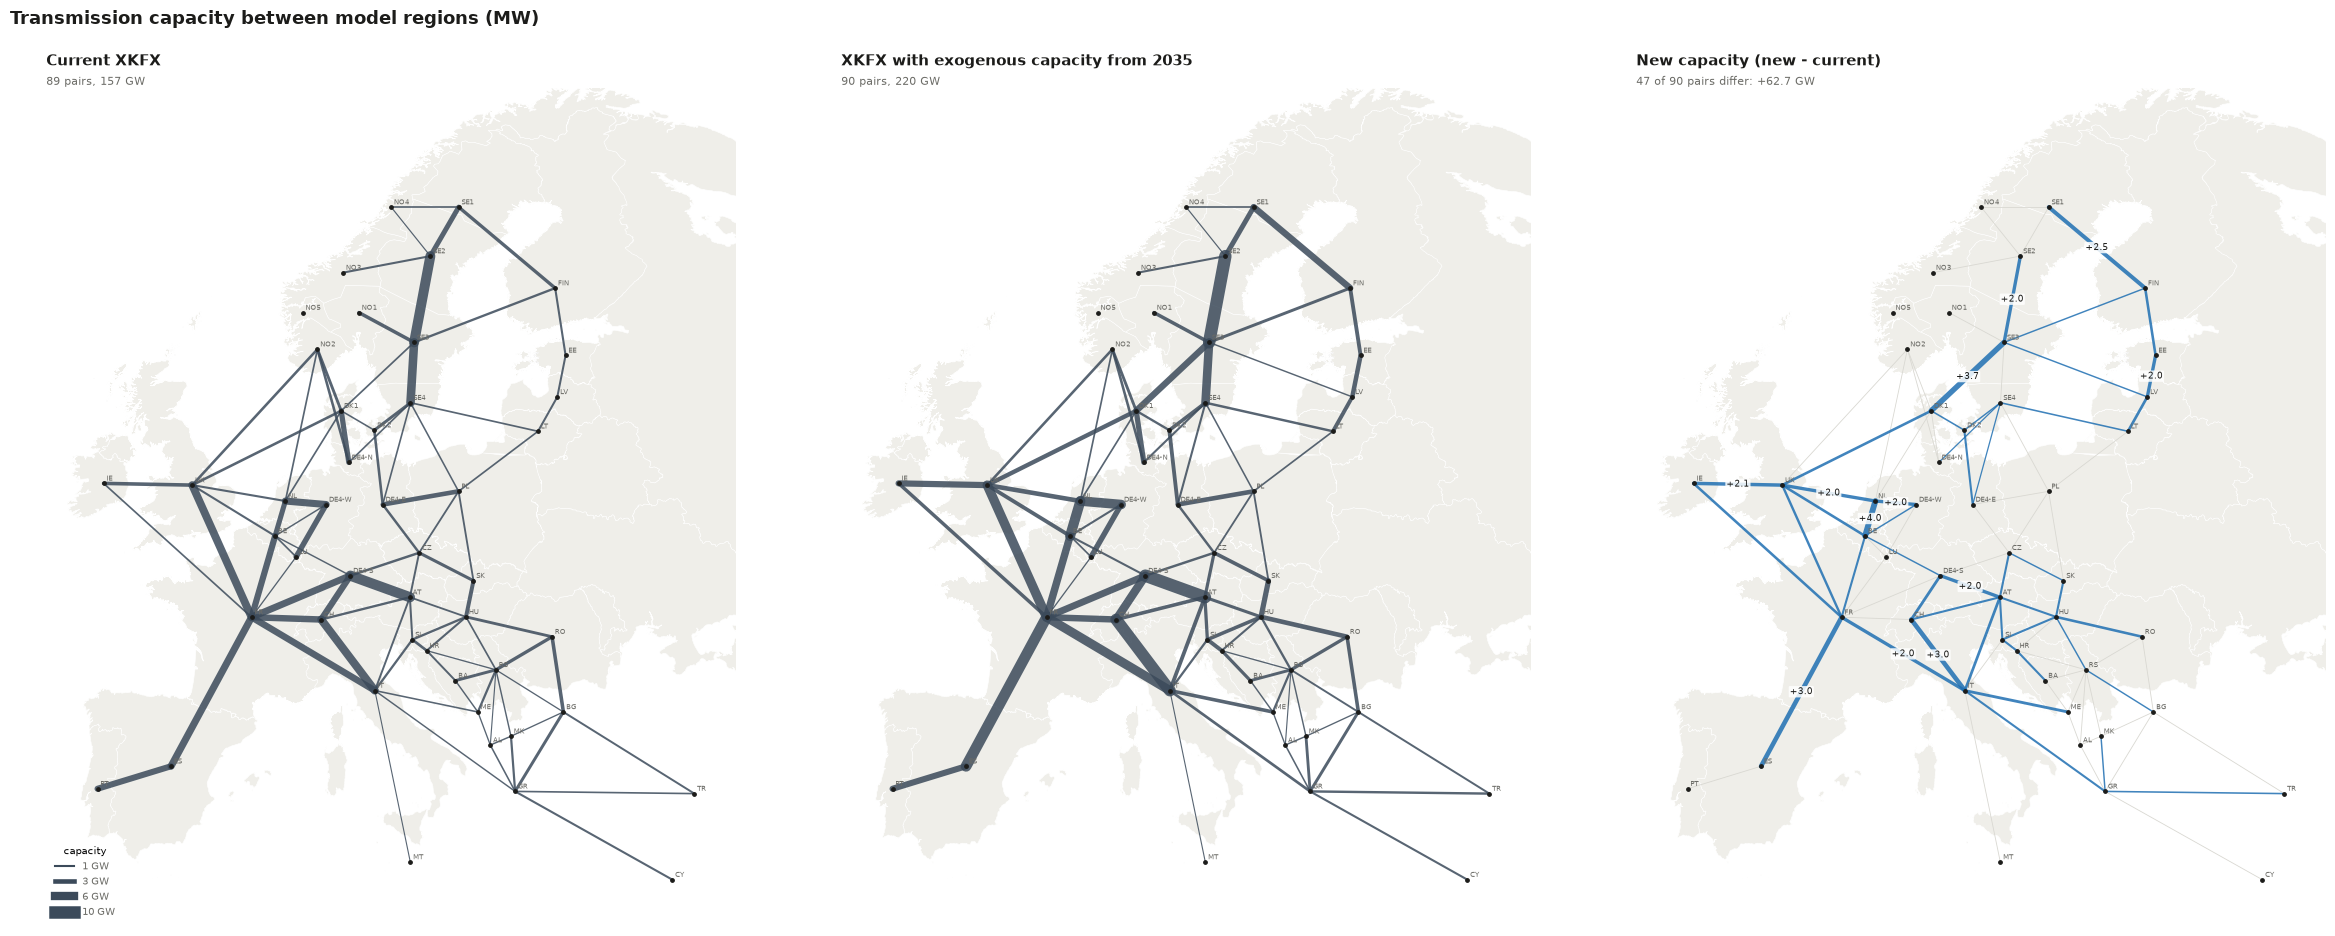

In [60]:
new_first = cur_m + new_tables[first]                              # XKFX of the first stage = existing + new capacity (new capacity read back from the text)
old_edges, new_edges = pair_values(cur_m), pair_values(new_first)
delta_xkfx = map_figure(old_edges, new_edges,
                        ["Current XKFX", f"XKFX with exogenous capacity from {first}", "New capacity (new - current)"],
                        "Transmission capacity between model regions (MW)", label_min=MAP_LABEL_MIN_MW, signed=False)

## 10. Maps: XMAXINV and the new exogenous capacity

Same maps for the current `XMAXINV` (existing grid + candidates up to 2035, symmetrised) and the new total `XKFX` of the first stage. They are expected to be equal; the right map shows `XKFX` with the new capacity minus `XMAXINV` for the pairs that differ (blue = higher in `XKFX`, orange = lower), all labelled. Pairs without a difference are drawn as grey hairlines.

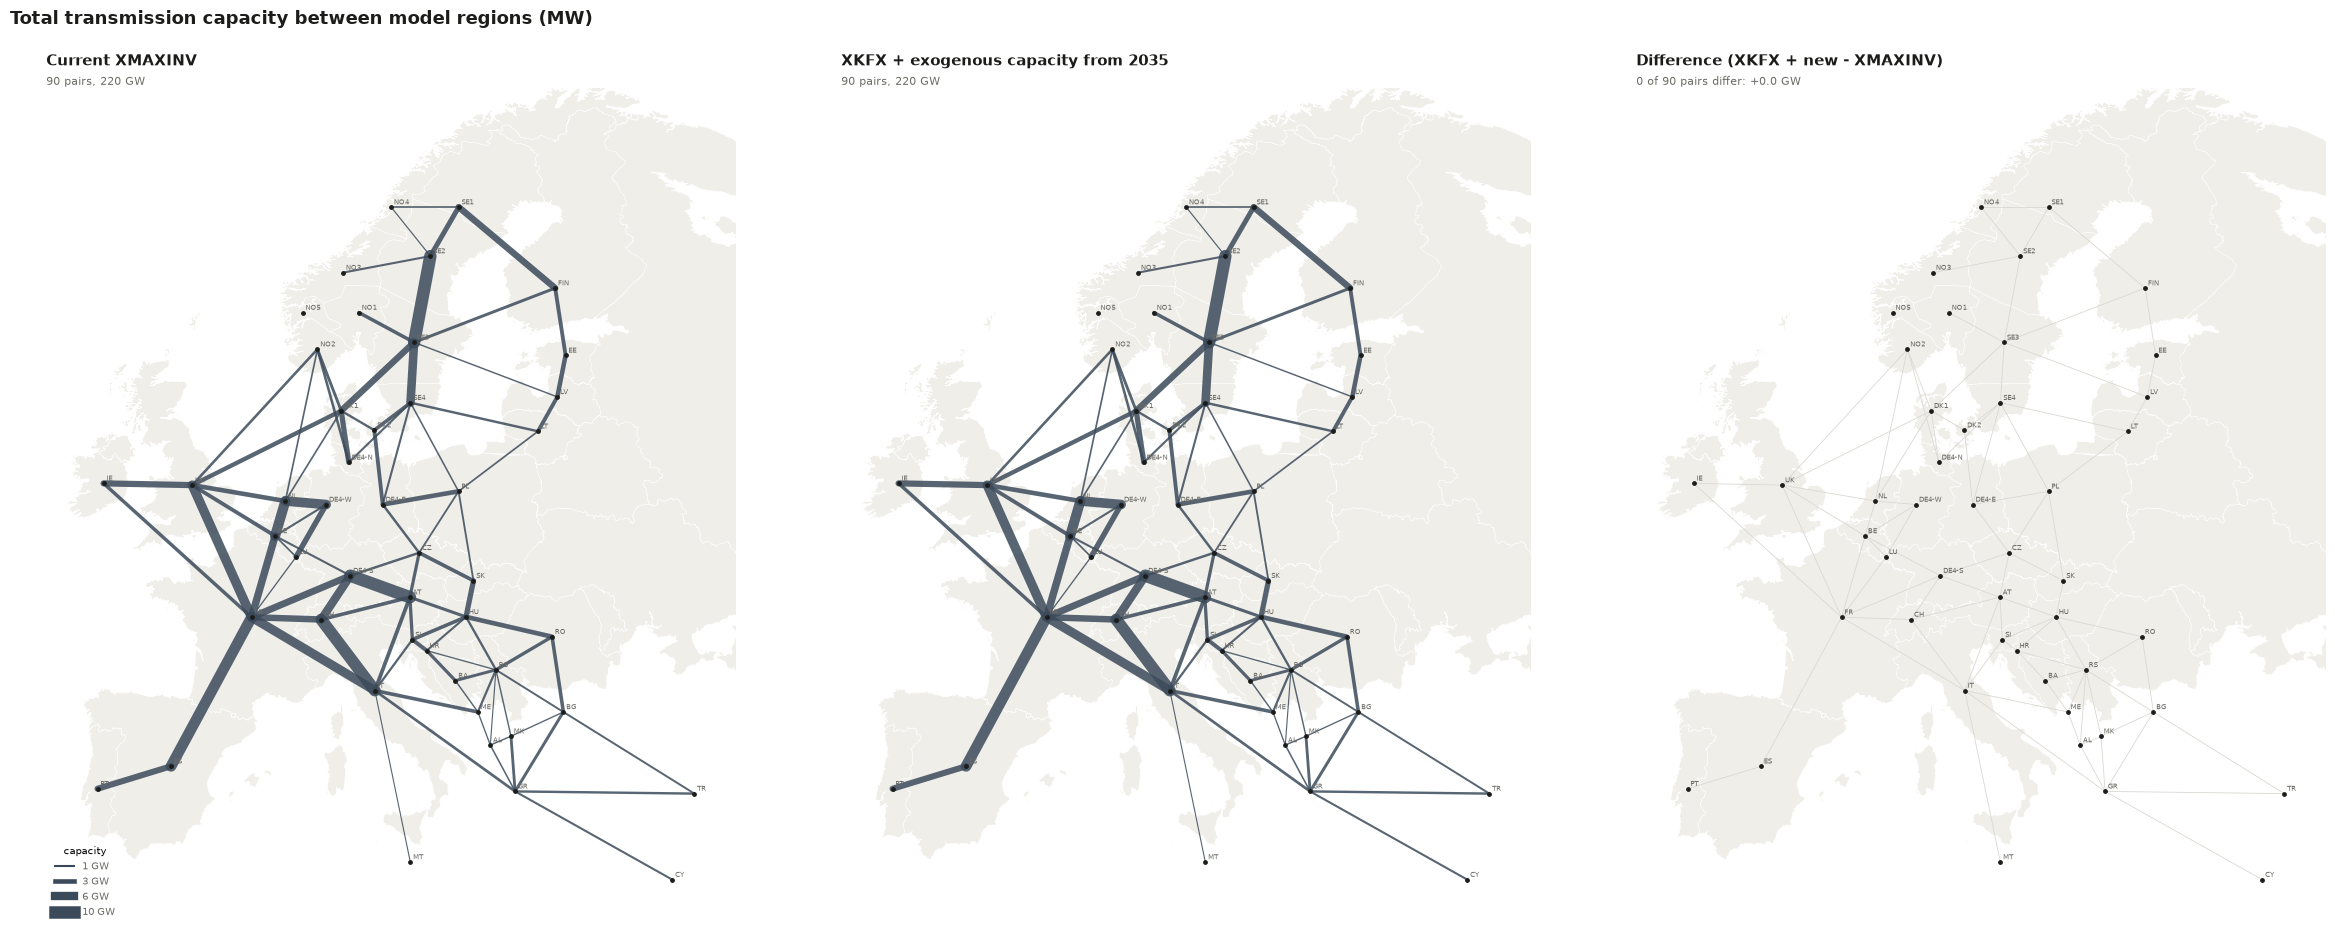

0 region pairs differ: none


In [61]:
xm_edges = pair_values(xm_m)
tot_edges = pair_values(np.maximum(new_first, new_first.T))
delta_xm = map_figure(xm_edges, tot_edges,
                      ["Current XMAXINV", f"XKFX + exogenous capacity from {first}", "Difference (XKFX + new - XMAXINV)"],
                      "Total transmission capacity between model regions (MW)", label_min=0, signed=True)
print(f"{len(delta_xm)} region pairs differ:", ", ".join(f"{a}-{b} {v:+,.0f} MW" for (a, b), v in sorted(delta_xm.items())) or "none")

## 11. Use in the model

1. `base/data/XKFX.inc` now ends with the generated block. It is only active when the option `XKFX_EXOGENOUS` is `yes`: add `$setglobal XKFX_EXOGENOUS yes` to `balopt.opt` (before the data is read), or change the default in the line `$if not setglobal XKFX_EXOGENOUS ...` in `XKFX.inc`. With the option off, `XKFX` is exactly as before. The original is saved once as `XKFX_before_exogenous.inc`; running the notebook again replaces the block between the BEGIN and END lines.
2. Endogenous transmission investment is then not needed for these lines: set `$setglobal TransInvest NO` in `balopt.opt`, or keep it on and make `XMAXINV` the remaining headroom *on top of* the new `XKFX` (the model caps new investment only, `VXKNACCUMNET.UP = XMAXINV`).
3. Simulated years are set in `Y.inc`. With `2030, 2050` the 2035 stage reaches only 2050.